# Week 9- START

## Select the Winning Model

This notebook compares all nine models built in Weeks 6 to 8 on the same validation folds, selects the winning model, predicts how it will perform on unseen data, and then scores it once on the test set, which has not been used until now.

| Week | Approach | Models |
|---|---|---|
| 6 | Single models | Tuned logistic regression, tuned random forest, tuned gradient boosting |
| 7 | Neural network (MLP) | Variations 1, 2, 3 |
| 8 | Stacking ensemble | Variations 1, 2, 3 |

**Validation design (same as Weeks 6 to 8):** 5-fold stratified cross-validation repeated 3 times on the training set, giving 15 train/validation splits. Every model is scored on exactly the same 15 splits, so results can be compared fold by fold. PR-AUC is the main metric because only about 15% of customers respond.

### 9.0 Setup

In [16]:
# Libraries
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, log_loss, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# MLPClassifier warns when it stops at max_iter before fully converging, which is expected
# for the larger networks (same as Week 7), so the warning is hidden to keep the output readable
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42

In [17]:
# Paths to the processed training and test sets created in Weeks 3 to 5
DATA = Path("../data/processed")
TRAIN_PATH = DATA / "train_model_reduced.csv"
TEST_PATH = DATA / "test_model_reduced.csv"
FIG_DIR = Path("../figures")
MODEL_DIR = Path("../models")
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for path in (TRAIN_PATH, TEST_PATH):
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run the Week 3 to 5 notebooks first, "
                                "or update the file name above.")

# Load features and target
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
X, y = train.drop(columns="Response"), train["Response"]
X_test, y_test = test.drop(columns="Response"), test["Response"]

# The test set must have the same columns, in the same order, as the training set
assert list(X_test.columns) == list(X.columns), "Training and test columns do not match"

print(f"Training set: {X.shape[0]:,} customers, {X.shape[1]} features, {y.mean():.1%} responders")
print(f"Test set:     {X_test.shape[0]:,} customers, {y_test.mean():.1%} responders")

Training set: 1,608 customers, 27 features, 14.6% responders
Test set:     412 customers, 15.3% responders


In [18]:
# The same 15 train/validation splits used in Weeks 6 to 8
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE).split(X, y))
print(f"{len(splits)} splits, about {len(splits[0][1])} validation customers each")

15 splits, about 322 validation customers each


### 9.1 The nine models

Each model uses the final settings chosen in its week. The random forest's settings are recovered by rerunning the Week 6 search, so they match Week 6 exactly. The stacking ensembles reuse the Week 6 and Week 7 models as base models.

Models are ordered from simplest to most complex: the linear model first, then the neural networks from smallest to largest, then the tree ensembles (gradient boosting with shallow trees, then the random forest with deeper trees), and last the stacking ensembles, because each one contains several of the other models. This order is used by the selection rule in 9.3 and the bias-variance chart in 9.4.

In [19]:
# Week 6: single models with their tuned settings
lr_w6 = LogisticRegression(C=3, solver="liblinear", max_iter=5000)   # L2 penalty is the default
gb_w6 = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=2,
                                   subsample=0.8, random_state=RANDOM_STATE)

# Random forest: rerun the Week 6 search (same grid, same 15 splits, best by PR-AUC) to recover
# its tuned settings exactly
rf_search = GridSearchCV(
    RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=1),
    {"max_depth": [4, 8, None], "min_samples_leaf": [5, 10], "class_weight": [None, "balanced_subsample"]},
    scoring="average_precision", cv=splits, n_jobs=-1).fit(X, y)
rf_w6 = rf_search.best_estimator_
print("Random forest settings (Week 6 search):", rf_search.best_params_)
print(f"Random forest validation PR-AUC in the search: {rf_search.best_score_:.3f}")

Random forest settings (Week 6 search): {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 5}
Random forest validation PR-AUC in the search: 0.650


In [20]:
# Week 7: neural network variations (scaler inside the pipeline)
# Settings for each variation: (hidden layer sizes, alpha), as in the Week 7 notebook
MLP_SETTINGS = {
    "W7 MLP Variation 1": ((8,), 3.0),
    "W7 MLP Variation 2": ((16,), 1.0),
    "W7 MLP Variation 3": ((64, 32), 0.001),
}

def make_mlp(hidden, alpha):
    return make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, activation="relu",
                                       solver="adam", learning_rate_init=0.001,
                                       max_iter=500, random_state=RANDOM_STATE))

mlps = {name: make_mlp(*settings) for name, settings in MLP_SETTINGS.items()}

# Week 8: stacking ensembles of the Week 6 and Week 7 models
base_models = {"lr": lr_w6, "gb": gb_w6, "mlp": mlps["W7 MLP Variation 1"]}

def make_stack(base_keys, passthrough, meta_C):
    return StackingClassifier(
        estimators=[(k, base_models[k]) for k in base_keys],
        final_estimator=make_pipeline(StandardScaler(), LogisticRegression(C=meta_C, max_iter=5000)),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        stack_method="predict_proba", passthrough=passthrough, n_jobs=-1)

# All nine models, from simplest to most complex
models = {
    "W6 Logistic regression": lr_w6,
    "W7 MLP Variation 1": mlps["W7 MLP Variation 1"],
    "W7 MLP Variation 2": mlps["W7 MLP Variation 2"],
    "W7 MLP Variation 3": mlps["W7 MLP Variation 3"],
    "W6 Gradient boosting": gb_w6,
    "W6 Random forest": rf_w6,
    "W8 Stack Variation 1": make_stack(["lr", "mlp"], passthrough=False, meta_C=1.0),
    "W8 Stack Variation 2": make_stack(["lr", "gb", "mlp"], passthrough=False, meta_C=1.0),
    "W8 Stack Variation 3": make_stack(["lr", "gb", "mlp"], passthrough=True, meta_C=0.1),
}
complexity_rank = {name: i for i, name in enumerate(models)}
print(f"{len(models)} models defined")

9 models defined


### 9.2 Evaluate all nine models on the validation folds

Each model is trained on the training part of every split and scored on both the training part and the validation part. Precision, recall, and F1 use a 0.5 probability cutoff, as in earlier weeks. Log loss measures how far the predicted probabilities are from what actually happened (lower is better); it is the error metric used in the bias-variance chart.

The stacking ensembles retrain their base models several times per split, so this cell takes several minutes.

In [21]:
# Score one model on all 15 splits; returns one row per split and dataset
def evaluate(model, name):
    rows = []
    for fold, (tr, va) in enumerate(splits):
        fitted = clone(model).fit(X.iloc[tr], y.iloc[tr])
        for part, idx in (("Training", tr), ("Validation", va)):
            prob = fitted.predict_proba(X.iloc[idx])[:, 1]
            true = y.iloc[idx]
            rows.append({"model": name, "fold": fold, "set": part,
                         "PR-AUC": average_precision_score(true, prob),
                         "ROC-AUC": roc_auc_score(true, prob),
                         "Precision": precision_score(true, prob >= 0.5, zero_division=0),
                         "Recall": recall_score(true, prob >= 0.5),
                         "F1": f1_score(true, prob >= 0.5),
                         "Log loss": log_loss(true, prob)})
    return pd.DataFrame(rows)

results = []
for name, model in models.items():
    results.append(evaluate(model, name))
    print(f"Done: {name}")
results = pd.concat(results, ignore_index=True)

Done: W6 Logistic regression
Done: W7 MLP Variation 1
Done: W7 MLP Variation 2
Done: W7 MLP Variation 3
Done: W6 Gradient boosting
Done: W6 Random forest
Done: W8 Stack Variation 1
Done: W8 Stack Variation 2
Done: W8 Stack Variation 3


In [22]:
# Mean training and validation metrics for each model, in complexity order
metrics = ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "Log loss"]
summary = (results.groupby(["model", "set"])[metrics].mean()
           .unstack("set").swaplevel(axis=1).sort_index(axis=1, level=0))
summary = summary.loc[list(models)]
print(summary.round(3).to_string())

set                    Training                                          Validation                                         
                             F1 Log loss PR-AUC Precision ROC-AUC Recall         F1 Log loss PR-AUC Precision ROC-AUC Recall
model                                                                                                                       
W6 Logistic regression    0.664    0.204  0.772     0.784   0.941  0.576      0.633    0.227  0.732     0.740   0.930  0.558
W7 MLP Variation 1        0.645    0.210  0.779     0.832   0.943  0.527      0.596    0.229  0.725     0.780   0.928  0.486
W7 MLP Variation 2        0.745    0.162  0.867     0.867   0.968  0.654      0.632    0.227  0.722     0.750   0.927  0.551
W7 MLP Variation 3        1.000    0.003  1.000     1.000   1.000  1.000      0.623    0.567  0.678     0.673   0.914  0.585
W6 Gradient boosting      0.739    0.176  0.885     0.935   0.969  0.612      0.560    0.248  0.693     0.781   0.910  0.442


### 9.3 Compare the nine models and select the winner

The comparison uses validation PR-AUC. Because scores vary from fold to fold, each model's standard error (fold standard deviation divided by the square root of 15) shows how precisely its mean is measured.

**Selection rule (one standard error rule):** find the model with the highest mean validation PR-AUC, then choose the least complex model whose mean is within one standard error of it. When models perform about equally, the simpler one is preferred because it is cheaper to run, easier to explain, and less likely to overfit.

In [23]:
# Validation PR-AUC by model and fold
val = results[results["set"] == "Validation"].pivot(index="fold", columns="model", values="PR-AUC")[list(models)]
train_pr = results[results["set"] == "Training"].groupby("model")["PR-AUC"].mean()

comparison = pd.DataFrame({
    "training PR-AUC": train_pr,
    "validation PR-AUC": val.mean(),
    "gap (train - validation)": train_pr - val.mean(),
    "validation SD": val.std(),
    "standard error": val.std() / np.sqrt(len(val)),
}).loc[list(models)]
comparison["rank"] = comparison["validation PR-AUC"].rank(ascending=False).astype(int)
print(comparison.round(3).to_string())

                        training PR-AUC  validation PR-AUC  gap (train - validation)  validation SD  standard error  rank
model                                                                                                                    
W6 Logistic regression            0.772              0.732                     0.040          0.068           0.017     2
W7 MLP Variation 1                0.779              0.725                     0.054          0.061           0.016     5
W7 MLP Variation 2                0.867              0.722                     0.145          0.053           0.014     6
W7 MLP Variation 3                1.000              0.678                     0.322          0.059           0.015     8
W6 Gradient boosting              0.885              0.693                     0.193          0.060           0.016     7
W6 Random forest                  0.968              0.650                     0.317          0.066           0.017     9
W8 Stack Variation 1    

In [24]:
# Apply the one standard error rule
best_mean = comparison["validation PR-AUC"].idxmax()
threshold = comparison.loc[best_mean, "validation PR-AUC"] - comparison.loc[best_mean, "standard error"]
eligible = comparison[comparison["validation PR-AUC"] >= threshold].index
winner = min(eligible, key=complexity_rank.get)

print(f"Highest mean validation PR-AUC: {best_mean} ({comparison.loc[best_mean, 'validation PR-AUC']:.3f})")
print(f"One standard error threshold:   {threshold:.3f}")
print(f"Models within the threshold:    {', '.join(eligible)}")
print(f"Selected model (least complex within threshold): {winner}")

# Fold by fold comparison of the selected model with every other model
diff = val.sub(val[winner], axis=0)
fold_table = pd.DataFrame({"mean difference vs selected": diff.mean(),
                           "folds better than selected (of 15)": (diff > 0).sum()}).drop(index=winner)
print("\n" + fold_table.round(3).to_string())

Highest mean validation PR-AUC: W8 Stack Variation 2 (0.735)
One standard error threshold:   0.719
Models within the threshold:    W6 Logistic regression, W7 MLP Variation 1, W7 MLP Variation 2, W8 Stack Variation 1, W8 Stack Variation 2, W8 Stack Variation 3
Selected model (least complex within threshold): W6 Logistic regression

                      mean difference vs selected  folds better than selected (of 15)
model                                                                                
W7 MLP Variation 1                         -0.007                                   6
W7 MLP Variation 2                         -0.010                                   7
W7 MLP Variation 3                         -0.054                                   3
W6 Gradient boosting                       -0.040                                   3
W6 Random forest                           -0.082                                   2
W8 Stack Variation 1                       -0.001                

### 9.4 Bias-variance chart

The chart shows training and validation log loss (lower is better) for each model, ordered from simplest to most complex. Training error shows bias: a model too simple to capture the pattern has high error even on the data it learned from. The gap between training and validation error shows variance: a model that memorizes its training customers has low training error but much higher validation error. The dotted line is the log loss of a model with no features that predicts the overall response rate for every customer.

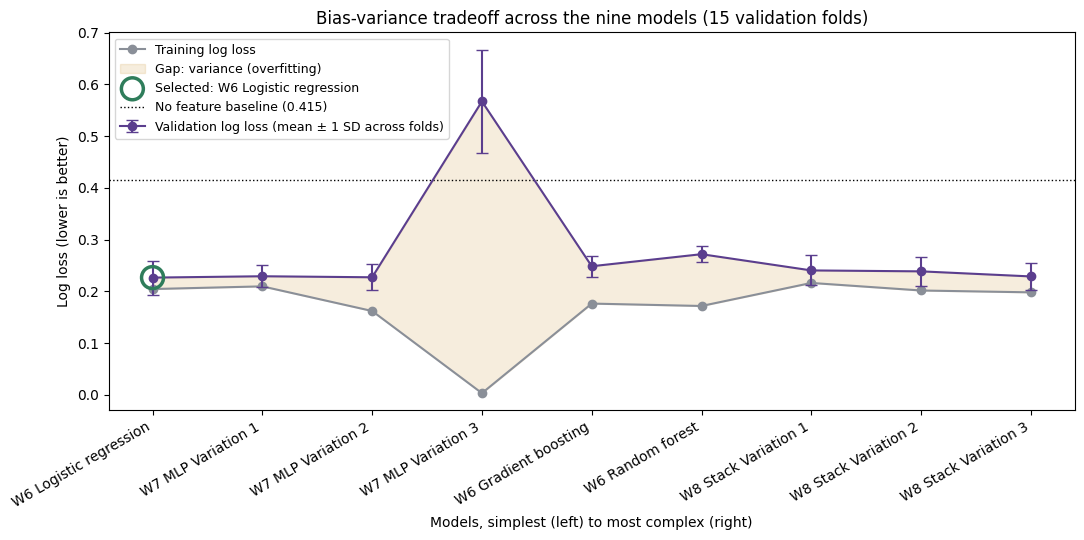

                        training log loss  validation log loss  gap (validation - training)
model                                                                                      
W6 Logistic regression              0.204                0.227                        0.022
W7 MLP Variation 1                  0.210                0.229                        0.020
W7 MLP Variation 2                  0.162                0.227                        0.065
W7 MLP Variation 3                  0.003                0.567                        0.564
W6 Gradient boosting                0.176                0.248                        0.072
W6 Random forest                    0.172                0.272                        0.100
W8 Stack Variation 1                0.216                0.240                        0.024
W8 Stack Variation 2                0.202                0.239                        0.037
W8 Stack Variation 3                0.198                0.229                  

In [25]:
# Training and validation log loss by model, simplest (left) to most complex (right)
order = list(models)
ll = results.groupby(["model", "set"])["Log loss"].agg(["mean", "std"]).unstack("set")
train_ll = ll[("mean", "Training")].loc[order]
val_ll = ll[("mean", "Validation")].loc[order]
val_sd = ll[("std", "Validation")].loc[order]

# Log loss of predicting the overall response rate for every customer
p = y.mean()
baseline_ll = -(p * np.log(p) + (1 - p) * np.log(1 - p))

xpos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(xpos, train_ll, marker="o", color="#8A8F98", label="Training log loss")
ax.errorbar(xpos, val_ll, yerr=val_sd, marker="o", color="#5B3E8E", capsize=4,
            label="Validation log loss (mean ± 1 SD across folds)")
ax.fill_between(xpos, train_ll, val_ll, color="#C98A1B", alpha=0.15, label="Gap: variance (overfitting)")
ax.scatter([order.index(winner)], [val_ll[winner]], s=250, facecolors="none", edgecolors="#2F7D5B",
           linewidths=2.5, zorder=5, label=f"Selected: {winner}")
ax.axhline(baseline_ll, ls=":", color="black", lw=1, label=f"No feature baseline ({baseline_ll:.3f})")
ax.set_xticks(xpos, order, rotation=30, ha="right")
ax.set_ylabel("Log loss (lower is better)")
ax.set_xlabel("Models, simplest (left) to most complex (right)")
ax.set_title("Bias-variance tradeoff across the nine models (15 validation folds)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "week9_bias_variance.png", dpi=150)
plt.show()

print(pd.DataFrame({"training log loss": train_ll, "validation log loss": val_ll,
                    "gap (validation - training)": val_ll - train_ll}).round(3).to_string())

### 9.5 Predict test performance before scoring the test set

The selected model's mean validation PR-AUC is the best estimate of its test PR-AUC. The expected range uses the fold-to-fold spread, adjusted for the test set's size: a larger test set gives a narrower range than a single validation fold.

This prediction is written down before the test set is scored, so it cannot be adjusted after seeing the result.

In [26]:
# Predicted test PR-AUC and an approximate 95% range
pred_mean = comparison.loc[winner, "validation PR-AUC"]
fold_size = len(splits[0][1])
pred_sd = comparison.loc[winner, "validation SD"] * np.sqrt(fold_size / len(X_test))
pred_low, pred_high = pred_mean - 1.96 * pred_sd, pred_mean + 1.96 * pred_sd
print(f"Predicted test PR-AUC for {winner}: {pred_mean:.3f} (expected range {pred_low:.3f} to {pred_high:.3f})")

Predicted test PR-AUC for W6 Logistic regression: 0.732 (expected range 0.615 to 0.849)


### 9.6 Winning model performance on the test set

The selected model is retrained on the full training set and scored once on the test set. A bootstrap (resampling test customers 1,000 times) gives a 95% interval for the test PR-AUC. The table shows the selected model's training, validation, and test metrics side by side.

In [27]:
# Retrain the selected model on all training data and score the test set
final_model = clone(models[winner]).fit(X, y)
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = test_prob >= 0.5

test_metrics = {"PR-AUC": average_precision_score(y_test, test_prob),
                "ROC-AUC": roc_auc_score(y_test, test_prob),
                "Precision": precision_score(y_test, test_pred, zero_division=0),
                "Recall": recall_score(y_test, test_pred),
                "F1": f1_score(y_test, test_pred),
                "Log loss": log_loss(y_test, test_prob)}

# Bootstrap 95% interval for test PR-AUC
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].sum() > 0:
        boot.append(average_precision_score(y_arr[idx], test_prob[idx]))
boot_low, boot_high = np.percentile(boot, [2.5, 97.5])

# Training, validation, and test metrics of the selected model side by side
three_way = pd.DataFrame({
    "training (mean of 15 folds)": summary.loc[winner].xs("Training"),
    "validation (mean of 15 folds)": summary.loc[winner].xs("Validation"),
    "test": pd.Series(test_metrics),
}).loc[metrics]
print(f"Selected model: {winner}\n")
print(three_way.round(3).to_string())
print(f"\nTest PR-AUC 95% bootstrap interval: {boot_low:.3f} to {boot_high:.3f}")
inside = pred_low <= test_metrics["PR-AUC"] <= pred_high
print(f"Predicted range {pred_low:.3f} to {pred_high:.3f}; test result inside it: {inside}")

Selected model: W6 Logistic regression

           training (mean of 15 folds)  validation (mean of 15 folds)   test
PR-AUC                           0.772                          0.732  0.665
ROC-AUC                          0.941                          0.930  0.883
Precision                        0.784                          0.740  0.692
Recall                           0.576                          0.558  0.429
F1                               0.664                          0.633  0.529
Log loss                         0.204                          0.227  0.281

Test PR-AUC 95% bootstrap interval: 0.559 to 0.766
Predicted range 0.615 to 0.849; test result inside it: True


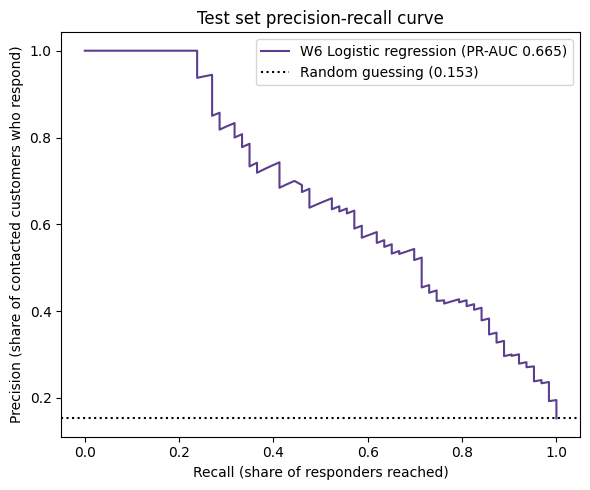

In [28]:
# Precision-recall curve on the test set
precision, recall, _ = precision_recall_curve(y_test, test_prob)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall, precision, color="#5B3E8E", label=f"{winner} (PR-AUC {test_metrics['PR-AUC']:.3f})")
ax.axhline(y_test.mean(), ls=":", color="black", label=f"Random guessing ({y_test.mean():.3f})")
ax.set_xlabel("Recall (share of responders reached)")
ax.set_ylabel("Precision (share of contacted customers who respond)")
ax.set_title("Test set precision-recall curve")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "week9_test_pr_curve.png", dpi=150)
plt.show()

In [29]:
# Business check: response rate among the top 40% of test customers by predicted probability,
# the contact strategy in the project's business case
top = pd.Series(test_prob).rank(ascending=False, method="first") <= 0.4 * len(test_prob)
top_rate = y_arr[top.to_numpy()].mean()
captured = y_arr[top.to_numpy()].sum() / y_arr.sum()
print(f"Response rate, all test customers:      {y_arr.mean():.1%}")
print(f"Response rate, top 40% by model score:  {top_rate:.1%} ({top_rate / y_arr.mean():.1f}x lift)")
print(f"Share of all responders in the top 40%: {captured:.1%}")

Response rate, all test customers:      15.3%
Response rate, top 40% by model score:  33.5% (2.2x lift)
Share of all responders in the top 40%: 87.3%


In [30]:
# Save the final model for the deployment work in later weeks
joblib.dump({"model": final_model, "features": list(X.columns), "name": winner},
            MODEL_DIR / "week9_final_model.joblib")
print("Saved:", MODEL_DIR / "week9_final_model.joblib")

Saved: ../models/week9_final_model.joblib


# Week 9- END